# C01 — Web summaries e métricas do Cell Ranger (ressequenciamento)

## Objetivo

Ler o que o próprio Cell Ranger reporta para as 14 bibliotecas
ressequenciadas (`data/allOuts`) e listar os problemas visíveis já nesse
nível, antes de qualquer análise de expressão.

## Dados

* `web_summary.html` — o JSON embutido na página (`const data = …`), que é a
  fonte dos números e gráficos que ela mostra;
* `metrics_summary.csv`;
* `_versions`, `_cmdline`, `_timestamp`, `_log`, `extras/telemetry`;
* `cell_types/Azimuth/cell_types.csv` — anotação automática (beta) do Cell
  Ranger, usada aqui só como medida de pureza do sorting.

## Método

1. Proveniência: versão, química, referência, parâmetros, falhas de execução.
2. Tabela de métricas e alarmes levantados pelo Cell Ranger.
3. Curvas de subamostragem do próprio pipeline: o que a profundidade comprou.
4. Métricas por paciente, pareando não estimulado × estimulado.
5. Chamada de células (barcode rank) e composição celular automática.
6. Tabela de problemas com gravidade.

As 14 bibliotecas vêm de 7 pacientes; MB e NP têm um paciente cada. Nada aqui
é teste estatístico — é descrição de qualidade por biblioteca.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import json
import re
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from functions import config, fmt as F, io, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "C01_websummary_metricas"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK

## 1. Proveniência das corridas

In [2]:
WS = {lib: io.load_web_summary(lib) for lib in LIBS}

rows = []
for lib in LIBS:
    rd = config.run_dir(lib)
    versions = json.loads((rd / "_versions").read_text())
    cmd = (rd / "_cmdline").read_text().strip()
    ts = dict(line.split(": ", 1) for line in (rd / "_timestamp").read_text().strip().splitlines())
    tel = sorted(p.name for p in (rd / "extras" / "telemetry").glob("*.json"))
    logtxt = (rd / "_log").read_text(errors="replace")
    t = io.web_summary_tables(WS[lib])
    rows.append({
        "library_id": lib,
        "pasta_allOuts": rd.name,
        "id_no_web_summary": WS[lib]["sample"]["id"],
        "cellranger": versions["pipelines"],
        "quimica": t["Chemistry"],
        "referencia": t["Transcriptome"],
        "include_introns": t["Include introns"],
        "bam_gerado": "--create-bam=false" not in cmd,
        "inicio": ts["start"],
        "duracao_h": round((pd.Timestamp(ts["end"]) - pd.Timestamp(ts["start"])).total_seconds() / 3600, 1),
        "falhas_antes_do_sucesso": sum(name.startswith("count_failure") for name in tel),
        "retries_no_log": len(re.findall(r"Attempting retry", logtxt)),
        "estado_final": "complete" if '"state": "complete"' in (rd / "_finalstate").read_text()[:400] else "?",
    })
prov = pd.DataFrame(rows).set_index("library_id")
io.save_table(prov, NB, "proveniencia", description="Proveniência das 14 corridas do Cell Ranger")
prov

,pasta_allOuts,id_no_web_summary,cellranger,quimica,referencia,include_introns,bam_gerado,inicio,duracao_h,falhas_antes_do_sucesso,retries_no_log,estado_final
library_id,,,,,,,,,,,,
CTH92_NS,CTH92_NS,CTH92_NS,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-10-09 03:16:42,5.7,0,0,complete
CTH92_ML,CTH92_ML,CTH92_ML,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-10-07 15:05:35,13.9,2,0,complete
CTH94_NS,CTH94_NS,CTH94_NS,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-09-28 02:17:46,29.2,0,0,complete
CTH94_ML,CTH94_ML,CTH94_ML,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-09-23 15:41:00,25.5,0,0,complete
CTH97_NS,CTH97_NS,CTH97_NS,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-09-29 16:15:54,11.7,0,0,complete
CTH97_ML,CTH97_ML,CTH97_ML,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-09-24 17:12:31,19.5,0,0,complete
PB20_NS,PB_20_SN,PB_20_SN,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-10-07 14:16:47,30.7,2,1,complete
PB20_ML,PB_20_ML,PB_20_ML,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-10-07 15:28:51,28.1,1,0,complete
PB21_NS,PB_21_NS,PB_21_NS,10.1.0,Single Cell 3' v3 (polyA),GRCh38-2024-A,True,False,2026-09-18 18:32:26,33.3,3,0,complete


In [3]:
assert (prov["estado_final"] == "complete").all(), "há corrida que não terminou"
assert prov["cellranger"].nunique() == 1 and prov["quimica"].nunique() == 1
assert prov["referencia"].nunique() == 1 and prov["include_introns"].nunique() == 1

renomeadas = prov.index[prov["pasta_allOuts"] != prov.index].tolist()
troca_sufixo = [lib for lib in LIBS if prov.loc[lib, "pasta_allOuts"].endswith("_SN")]

print(f"Cell Ranger {prov['cellranger'].iloc[0]} · {prov['quimica'].iloc[0]} · "
      f"{prov['referencia'].iloc[0]} · include_introns={prov['include_introns'].iloc[0]}")
print(f"BAM gerado em alguma corrida: {'sim' if prov['bam_gerado'].any() else 'não'}")
print(f"bibliotecas com nome diferente do canônico: {len(renomeadas)} → {renomeadas}")
print(f"com sufixo SN no lugar de NS: {[prov.loc[l, 'pasta_allOuts'] for l in troca_sufixo]}")
print(f"corridas com falha imediata antes do sucesso: "
      f"{int((prov['falhas_antes_do_sucesso'] > 0).sum())}; com retry no log: "
      f"{int((prov['retries_no_log'] > 0).sum())}; todas terminaram em 'complete'")

Cell Ranger 10.1.0 · Single Cell 3' v3 (polyA) · GRCh38-2024-A · include_introns=True
BAM gerado em alguma corrida: não
bibliotecas com nome diferente do canônico: 8 → ['PB20_NS', 'PB20_ML', 'PB21_NS', 'PB21_ML', 'MB34_NS', 'MB34_ML', 'HNP44_NS', 'HNP44_ML']
com sufixo SN no lugar de NS: ['PB_20_SN', 'MB_34_SN']
corridas com falha imediata antes do sucesso: 6; com retry no log: 1; todas terminaram em 'complete'


As 14 corridas usam a mesma versão, química, referência e parâmetros, e todas
terminaram. As falhas registradas na telemetria duram menos de um segundo
(erro de lançamento, antes de qualquer processamento) e o *retry* do log é do
escalonador; nenhuma afeta o resultado.

Dois pontos de proveniência importam para o que vem depois:

* **Não há BAM** (`--create-bam=false`). Sem alinhamentos não é possível
  reconstruir TCR nem genotipar, o que restringe os testes de doublets a
  evidência indireta (A03).
* **Os nomes mudaram.** Oito pastas diferem do `library_id` usado até aqui, e
  duas trocam `NS` por `SN`. O código original deriva o estímulo com
  `endswith("NS")`; aplicado a estes nomes, rotularia essas duas bibliotecas
  não estimuladas como estimuladas. Por isso toda a análise usa o
  `library_id` canônico (`functions/config.RESEQ_TO_CANONICAL`); a
  equivalência é verificada por barcodes em C02.

In [4]:
log.add("MINOR", "data/allOuts — nomes das pastas",
        "nomes das bibliotecas diferem dos usados na corrida anterior; duas usam o sufixo SN em vez de NS",
        evidence=f"{len(renomeadas)} de {len(LIBS)} pastas renomeadas; SN: "
                 f"{[prov.loc[l, 'pasta_allOuts'] for l in troca_sufixo]}",
        impact="a regra original `endswith('NS')` rotularia MB_34_SN e PB_20_SN como "
               "estimuladas, invertendo a condição de 2 das 14 bibliotecas sem erro algum",
        recommendation="usar o library_id canônico em todo o código (feito) e padronizar os "
                       "nomes na origem em corridas futuras")
log.add("INFO", "cellranger count --create-bam=false",
        "as corridas não geraram BAM",
        evidence="_cmdline das 14 bibliotecas",
        impact="sem alinhamentos não há reconstrução de TCR nem genotipagem; a hipótese de "
               "doublets só pode ser testada por evidência indireta",
        recommendation="se a prova direta de doublets for necessária, reprocessar com "
                       "--create-bam=true (ainda assim, com um doador por biblioteca, não há "
                       "demultiplexação genética)")

## 2. Métricas e alarmes

In [5]:
metrics = pd.DataFrame({lib: io.read_metrics(lib) for lib in LIBS}).T
diag = pd.DataFrame({lib: WS[lib]["diagnostics"] for lib in LIBS}).T
metrics = metrics.join(diag)
metrics.index.name = "library_id"

# o CSV e a página têm de contar a mesma história
for lib in LIBS:
    t = io.web_summary_tables(WS[lib])
    for campo in ["Estimated Number of Cells", "Number of Reads", "Sequencing Saturation",
                  "Fraction Reads in Cells", "Median Genes per Cell"]:
        assert np.isclose(io.parse_metric(t[campo]), metrics.loc[lib, campo]), (lib, campo)

SHORT = {
    "Estimated Number of Cells": "celulas",
    "Number of Reads": "reads",
    "Mean Reads per Cell": "reads_por_celula",
    "Median UMI Counts per Cell": "umis_medianos",
    "Median Genes per Cell": "genes_medianos",
    "Total Genes Detected": "genes_detectados",
    "Sequencing Saturation": "saturacao",
    "Fraction Reads in Cells": "reads_em_celulas",
    "Valid Barcodes": "barcodes_validos",
    "Valid UMI Sequences": "umis_validos",
    "Q30 Bases in Barcode": "q30_barcode",
    "Q30 Bases in RNA Read": "q30_rna",
    "Q30 Bases in UMI": "q30_umi",
    "Reads Mapped to Genome": "mapeados_genoma",
    "Reads Mapped Confidently to Genome": "conf_genoma",
    "Reads Mapped Confidently to Intergenic Regions": "conf_intergenico",
    "Reads Mapped Confidently to Intronic Regions": "conf_intronico",
    "Reads Mapped Confidently to Exonic Regions": "conf_exonico",
    "Reads Mapped Confidently to Transcriptome": "conf_transcriptoma",
    "Reads Mapped Antisense to Gene": "antisense",
    "tso_frac": "tso_frac",
    "low_support_umi_reads_frac": "reads_umi_baixo_suporte",
    "corrected_bc_frac": "barcodes_corrigidos",
}
m = metrics.rename(columns=SHORT)[list(SHORT.values())]
m.insert(0, "estimulo", [config.stimulation_of(l) for l in m.index])
m.insert(0, "classificacao", [config.classification_of(l) for l in m.index])
m.insert(0, "paciente", [config.patient_of(l) for l in m.index])

io.save_table(m, NB, "metricas_por_biblioteca",
              description="Métricas do Cell Ranger por biblioteca (frações em 0–1)")

vista = m[["celulas", "reads", "reads_por_celula", "umis_medianos", "genes_medianos",
           "saturacao", "reads_em_celulas", "conf_intronico", "antisense", "tso_frac"]]
F.styler(vista, {"celulas": F.n, "reads": F.compact, "reads_por_celula": F.n,
                 "umis_medianos": F.n, "genes_medianos": F.n, "saturacao": F.pct,
                 "reads_em_celulas": F.pct, "conf_intronico": F.pct, "antisense": F.pct,
                 "tso_frac": F.pct})

,celulas,reads,reads_por_celula,umis_medianos,genes_medianos,saturacao,reads_em_celulas,conf_intronico,antisense,tso_frac
library_id,,,,,,,,,,
CTH92_NS,851,"1,68 bi",1.970.584,9.866,3.121,"98,7%","57,6%","26,7%","13,0%","1,8%"
CTH92_ML,1.570,"1,76 bi",1.124.003,4.040,1.832,"98,8%","61,3%","30,1%","16,7%","3,8%"
CTH94_NS,6.090,"2,70 bi",443.895,11.815,3.661,"95,1%","90,1%","44,1%","19,7%","5,4%"
CTH94_ML,547,"1,43 bi",2.609.552,11.295,3.391,"98,9%","60,8%","27,8%","14,2%","6,9%"
CTH97_NS,1.628,"2,11 bi",1.293.457,8.578,2.894,"98,4%","78,0%","26,6%","16,8%","21,7%"
CTH97_ML,4.737,"1,80 bi",380.618,2.401,1.009,"98,6%","86,8%","12,8%","9,5%","3,4%"
PB20_NS,635,"1,77 bi",2.790.817,9.221,2.640,"99,2%","69,5%","23,9%","15,0%","11,5%"
PB20_ML,841,"1,64 bi",1.944.651,10.224,2.890,"98,9%","75,6%","22,8%","14,0%","8,4%"
PB21_NS,4.266,"1,54 bi",360.107,9.272,2.794,"94,2%","85,8%","22,2%","13,1%","13,6%"


In [6]:
qualidade = m[["barcodes_validos", "umis_validos", "q30_barcode", "q30_rna", "q30_umi",
               "mapeados_genoma", "conf_transcriptoma"]]
print("qualidade de leitura e mapeamento — mínimo e máximo entre as 14 bibliotecas")
for col in qualidade:
    print(f"  {col:22s} {F.pct(qualidade[col].min())} a {F.pct(qualidade[col].max())}")

qualidade de leitura e mapeamento — mínimo e máximo entre as 14 bibliotecas
  barcodes_validos       93,9% a 97,4%
  umis_validos           96,1% a 96,6%
  q30_barcode            97,4% a 97,8%
  q30_rna                95,0% a 97,5%
  q30_umi                97,9% a 98,2%
  mapeados_genoma        87,9% a 98,3%
  conf_transcriptoma     62,3% a 82,2%


In [7]:
alarmes = pd.concat(
    [io.web_summary_alarms(WS[lib]).assign(library_id=lib) for lib in LIBS], ignore_index=True)
alarmes = alarmes[["library_id", "level", "title", "value", "message"]]
io.save_table(alarmes, NB, "alarmes_cellranger",
              description="Alarmes levantados pelo Cell Ranger nos web summaries", index=False)

print(f"alarmes (exceto o aviso promocional): {len(alarmes)} em "
      f"{alarmes['library_id'].nunique()} de {len(LIBS)} bibliotecas; níveis: "
      f"{sorted(alarmes['level'].unique())}\n")
print(alarmes.groupby("title")["library_id"].agg(lambda s: ", ".join(s)).to_string())
print()
for titulo, msg in alarmes.drop_duplicates("title")[["title", "message"]].itertuples(index=False):
    print(f"• {titulo}\n  {msg}\n")

alarmes (exceto o aviso promocional): 8 em 7 de 14 bibliotecas; níveis: ['WARN']

title
High Fraction of Reads Mapped Antisense to Genes                        MB34_NS, HNP44_NS, HNP44_ML
Low Fraction Reads in Cells                         CTH92_NS, CTH92_ML, CTH94_ML, PB20_NS, HNP44_NS

• Low Fraction Reads in Cells
  Ideal > 70%. Application performance may be affected. Many of the reads were not assigned to cell-associated barcodes. This could be caused by high levels of ambient RNA or by a significant population of cells with a low RNA content, which the algorithm did not call as cells. The latter case can be addressed by inspecting the data to determine the appropriate cell count and using --force-cells.

• High Fraction of Reads Mapped Antisense to Genes
  Ideal < 20%. Rates of up to 40% are common for single nuclei samples. Higher fraction of antisense reads may indicate use of an incorrect chemistry type, or an issue with the reference transcriptome.



O Cell Ranger só levanta dois tipos de alarme, ambos em nível `WARN`. Nenhum
alarme de qualidade de sequenciamento (Q30, barcodes válidos) ou de
mapeamento ao transcriptoma apareceu, e os valores impressos acima estão
altos em todas as bibliotecas: **o sequenciamento em si está bom**. Os
problemas estão na biblioteca, não na leitura dela.

## 3. O que a profundidade comprou

O Cell Ranger subamostra os reads e recalcula saturação, genes medianos e
UMIs medianos por célula. Essas curvas respondem diretamente se mais
sequenciamento ainda rende. A 10x recomenda no mínimo 20 mil pares de reads
por célula para a química 3' v3; 50 mil é uma profundidade usual.

In [8]:
curvas = {lib: io.web_summary_curves(WS[lib]) for lib in LIBS}


def no_ponto(df, col, depth):
    """Valor da curva `col` na profundidade `depth` (NaN além do observado)."""
    x, y = df["mean_reads_per_cell"].to_numpy(), df[col].to_numpy()
    return float(np.interp(depth, x, y)) if depth <= x[-1] else np.nan


def profundidade_para(df, col, alvo):
    """Menor profundidade em que a curva `col` atinge `alvo`."""
    x, y = df["mean_reads_per_cell"].to_numpy(), df[col].to_numpy()
    return float(np.interp(alvo, y, x))


linhas = []
for lib in LIBS:
    c = curvas[lib]
    fim = c.iloc[-1]
    d = fim["mean_reads_per_cell"]
    linhas.append({
        "library_id": lib,
        "reads_por_celula": d,
        "x_minimo_10x": d / 20_000,
        "sat_20k": no_ponto(c, "saturation", 20_000),
        "sat_50k": no_ponto(c, "saturation", 50_000),
        "sat_200k": no_ponto(c, "saturation", 200_000),
        "sat_final": fim["saturation"],
        "genes_50k": no_ponto(c, "median_genes", 50_000),
        "genes_final": fim["median_genes"],
        "umis_50k": no_ponto(c, "median_umis", 50_000),
        "umis_final": fim["median_umis"],
        "prof_90pct_genes": profundidade_para(c, "median_genes", 0.9 * fim["median_genes"]),
        "genes_metade_da_prof": no_ponto(c, "median_genes", d / 2),
        "umis_metade_da_prof": no_ponto(c, "median_umis", d / 2),
    })
prof = pd.DataFrame(linhas).set_index("library_id")
prof["ganho_genes_apos_50k"] = prof["genes_final"] / prof["genes_50k"] - 1
prof["frac_reads_para_90pct_genes"] = prof["prof_90pct_genes"] / prof["reads_por_celula"]
prof["ganho_genes_ultima_duplicacao"] = prof["genes_final"] / prof["genes_metade_da_prof"] - 1
prof["ganho_umis_ultima_duplicacao"] = prof["umis_final"] / prof["umis_metade_da_prof"] - 1
prof["reads_por_umi"] = 1 / (1 - prof["sat_final"])
io.save_table(prof, NB, "retorno_da_profundidade",
              description="Saturação, genes e UMIs medianos em profundidades subamostradas "
                          "(curvas do web summary)")

F.styler(prof[["reads_por_celula", "x_minimo_10x", "sat_50k", "sat_200k", "sat_final",
               "reads_por_umi", "genes_50k", "genes_final", "prof_90pct_genes",
               "frac_reads_para_90pct_genes", "ganho_genes_ultima_duplicacao"]],
         {"reads_por_celula": F.n, "x_minimo_10x": lambda v: F.x(v, 0), "sat_50k": F.pct,
          "sat_200k": F.pct, "sat_final": F.pct, "reads_por_umi": lambda v: F.f(v, 0),
          "genes_50k": F.n, "genes_final": F.n, "prof_90pct_genes": F.n,
          "frac_reads_para_90pct_genes": F.pct,
          "ganho_genes_ultima_duplicacao": lambda v: F.pct(v, 1, signed=True)})

,reads_por_celula,x_minimo_10x,sat_50k,sat_200k,sat_final,reads_por_umi,genes_50k,genes_final,prof_90pct_genes,frac_reads_para_90pct_genes,ganho_genes_ultima_duplicacao
library_id,,,,,,,,,,,
CTH92_NS,1.970.584,99×,"65,8%","88,7%","98,7%",75,2.415,3.121,188.912,"9,6%","+2,3%"
CTH92_ML,1.124.002,56×,"79,2%","93,4%","98,8%",83,1.526,1.832,111.570,"9,9%","+2,1%"
CTH94_NS,443.895,22×,"69,4%","89,9%","95,1%",21,3.041,3.661,94.017,"21,2%","+3,6%"
CTH94_ML,2.609.552,130×,"62,3%","82,0%","98,9%",88,2.614,3.391,229.026,"8,8%","+1,7%"
CTH97_NS,1.293.457,65×,"71,0%","90,0%","98,4%",62,2.336,2.894,136.704,"10,6%","+2,5%"
CTH97_ML,380.617,19×,"91,0%","97,5%","98,6%",74,890,1.009,65.252,"17,1%","+3,6%"
PB20_NS,2.790.816,140×,"69,2%","84,6%","99,2%",123,2.054,2.640,238.174,"8,5%","+1,7%"
PB20_ML,1.944.650,97×,"69,5%","90,3%","98,9%",89,2.281,2.890,178.058,"9,2%","+1,8%"
PB21_NS,360.106,18×,"70,9%","90,3%","94,2%",17,2.237,2.794,105.179,"29,2%","+5,4%"


In [9]:
n_sat95 = int((prof["sat_final"] >= 0.95).sum())
med_sat50 = prof["sat_50k"].median()
med_frac90 = prof["frac_reads_para_90pct_genes"].median()

print(f"total sequenciado: {F.compact(m['reads'].sum())} de reads "
      f"({F.compact(m['reads'].min())} a {F.compact(m['reads'].max())} por biblioteca)")
print(f"profundidade final: {F.n(prof['reads_por_celula'].min())} a "
      f"{F.n(prof['reads_por_celula'].max())} reads/célula = "
      f"{F.x(prof['x_minimo_10x'].min(), 0)} a {F.x(prof['x_minimo_10x'].max(), 0)} o mínimo da 10x")
print(f"saturação final: {F.pct(prof['sat_final'].min())} a {F.pct(prof['sat_final'].max())}; "
      f"≥ 95% em {n_sat95} de {len(LIBS)} bibliotecas")
print(f"reads por UMI na profundidade final (1/(1−saturação)): mediana "
      f"{F.f(prof['reads_por_umi'].median(), 0)}, de {F.f(prof['reads_por_umi'].min(), 0)} a "
      f"{F.f(prof['reads_por_umi'].max(), 0)}")
print(f"saturação a 50 mil reads/célula: mediana {F.pct(med_sat50, 0)} "
      f"(de {F.pct(prof['sat_50k'].min(), 0)} a {F.pct(prof['sat_50k'].max(), 0)})")
print(f"saturação a 200 mil reads/célula: mediana {F.pct(prof['sat_200k'].median(), 0)} "
      f"(13 bibliotecas com essa profundidade)")
print(f"genes medianos ganhos de 50 mil reads/célula até o fim: mediana "
      f"{F.pct(prof['ganho_genes_apos_50k'].median(), 0, True)} "
      f"(de {F.pct(prof['ganho_genes_apos_50k'].min(), 0, True)} a "
      f"{F.pct(prof['ganho_genes_apos_50k'].max(), 0, True)})")
print(f"fração dos reads que bastou para 90% dos genes finais: mediana {F.pct(med_frac90, 0)} "
      f"(de {F.pct(prof['frac_reads_para_90pct_genes'].min(), 0)} a "
      f"{F.pct(prof['frac_reads_para_90pct_genes'].max(), 0)})")
print(f"última duplicação de profundidade (metade → total): genes "
      f"{F.pct(prof['ganho_genes_ultima_duplicacao'].median(), 1, True)} (mediana; máx. "
      f"{F.pct(prof['ganho_genes_ultima_duplicacao'].max(), 1, True)}), UMIs "
      f"{F.pct(prof['ganho_umis_ultima_duplicacao'].median(), 1, True)} (mediana; máx. "
      f"{F.pct(prof['ganho_umis_ultima_duplicacao'].max(), 1, True)})")

total sequenciado: 26,11 bi de reads (1,43 bi a 2,70 bi por biblioteca)
profundidade final: 142.741 a 12.769.386 reads/célula = 7× a 638× o mínimo da 10x
saturação final: 89,0% a 99,5%; ≥ 95% em 12 de 14 bibliotecas
reads por UMI na profundidade final (1/(1−saturação)): mediana 70, de 9 a 217
saturação a 50 mil reads/célula: mediana 69% (de 47% a 91%)
saturação a 200 mil reads/célula: mediana 89% (13 bibliotecas com essa profundidade)
genes medianos ganhos de 50 mil reads/célula até o fim: mediana +28% (de +13% a +54%)
fração dos reads que bastou para 90% dos genes finais: mediana 10% (de 9% a 40%)
última duplicação de profundidade (metade → total): genes +2,3% (mediana; máx. +7,4%), UMIs +3,0% (mediana; máx. +11,2%)


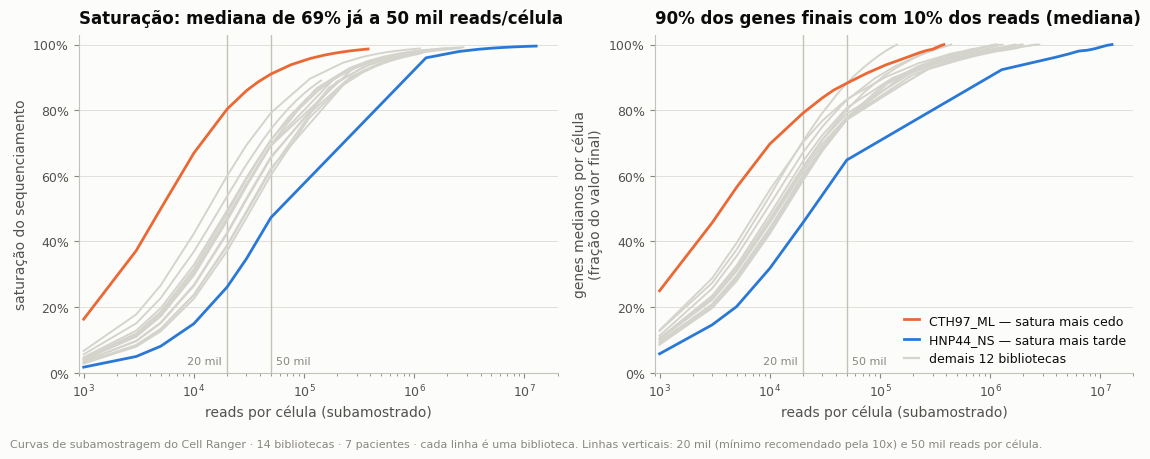

In [10]:
# Todas as 14 curvas em cinza; destacadas a que satura mais cedo e a mais tarde.
mais_cedo = prof["sat_50k"].idxmax()
mais_tarde = prof["sat_50k"].idxmin()
destaque = {mais_cedo: plotting.CATEGORICAL[1], mais_tarde: plotting.CATEGORICAL[0]}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for ax, col, ylabel, rel in [
        (axes[0], "saturation", "saturação do sequenciamento", False),
        (axes[1], "median_genes", "genes medianos por célula\n(fração do valor final)", True)]:
    for lib in LIBS:
        if lib in destaque:
            continue
        c = curvas[lib].iloc[1:]
        y = c[col] / c[col].iloc[-1] if rel else c[col]
        ax.plot(c["mean_reads_per_cell"], y, color=plotting.CONTEXT, lw=1.4, zorder=2)
    for lib, cor in destaque.items():
        c = curvas[lib].iloc[1:]
        y = c[col] / c[col].iloc[-1] if rel else c[col]
        ax.plot(c["mean_reads_per_cell"], y, color=cor, lw=2, zorder=4)
    for dpt, txt, ha, dx in [(20_000, "20 mil", "right", -4), (50_000, "50 mil", "left", 4)]:
        ax.axvline(dpt, color=INK["axis"], lw=1, zorder=1)
        ax.annotate(txt, (dpt, 0.02), xycoords=("data", "axes fraction"),
                    textcoords="offset points", xytext=(dx, 0), ha=ha, va="bottom",
                    fontsize=8, color=INK["muted"])
    ax.set_xscale("log")
    ax.set_xlim(900, 2e7)
    ax.set_ylim(0, 1.03)
    ax.set_xlabel("reads por célula (subamostrado)")
    ax.set_ylabel(ylabel)
    plotting.percent(ax)
axes[0].set_title(f"Saturação: mediana de {F.pct(med_sat50, 0)} já a 50 mil reads/célula")
axes[1].set_title(f"90% dos genes finais com {F.pct(med_frac90, 0)} dos reads (mediana)")
handles = [mpl.lines.Line2D([], [], color=destaque[mais_cedo], lw=2, label=f"{mais_cedo} — satura mais cedo"),
           mpl.lines.Line2D([], [], color=destaque[mais_tarde], lw=2, label=f"{mais_tarde} — satura mais tarde"),
           mpl.lines.Line2D([], [], color=plotting.CONTEXT, lw=1.6, label="demais 12 bibliotecas")]
axes[1].legend(handles=handles, loc="lower right")
fig.tight_layout()
plotting.note(fig, f"Curvas de subamostragem do Cell Ranger · {plotting.N_DESIGN} · cada linha é uma "
                   "biblioteca. Linhas verticais: 20 mil (mínimo recomendado pela 10x) e 50 mil reads por célula.")
tab_curvas = pd.concat([curvas[l].assign(library_id=l) for l in LIBS], ignore_index=True)
plotting.savefig(fig, NB, "retorno_da_profundidade",
                 description="Saturação e genes medianos em função da profundidade subamostrada",
                 data=tab_curvas, data_index=False)
plt.show()

**Leitura.** A saturação é a fração de reads que repetem uma molécula já
vista. Na profundidade final ela está tão alta que cada molécula foi lida, em
mediana, dezenas de vezes — e até mais de duzentas na biblioteca com menos
células.

A curva de genes mostra o retorno: as bibliotecas chegaram a 90% dos genes
por célula que têm hoje com uma fração pequena dos reads, e a última
duplicação de profundidade rendeu poucos pontos percentuais. O retorno não é
zero — entre 50 mil reads por célula e a profundidade final ainda entram
genes —, mas é fortemente decrescente, e o trecho final da curva é quase
plano.

Isso é propriedade da biblioteca: o número de moléculas distintas que ela
contém (a complexidade) é finito. Quanto desse ganho residual chegou às
citocinas é medido em C02 (contra a corrida antiga) e C03 (molécula a
molécula).

In [11]:
log.add("CRITICAL", "todas as bibliotecas — profundidade × complexidade",
        "as bibliotecas estão saturadas: o sequenciamento adicional lê repetidamente as mesmas moléculas",
        evidence=f"saturação final {F.pct(prof['sat_final'].min())}–{F.pct(prof['sat_final'].max())} "
                 f"(≥ 95% em {n_sat95}/14); mediana de {F.f(prof['reads_por_umi'].median(), 0)} "
                 f"reads por UMI (máx. {F.f(prof['reads_por_umi'].max(), 0)}); profundidade "
                 f"{F.x(prof['x_minimo_10x'].min(), 0)}–{F.x(prof['x_minimo_10x'].max(), 0)} o "
                 f"mínimo da 10x; 90% dos genes por célula já apareciam com "
                 f"{F.pct(med_frac90, 0)} dos reads (mediana); a última duplicação de "
                 f"profundidade rendeu {F.pct(prof['ganho_genes_ultima_duplicacao'].median(), 1, True)} "
                 f"de genes e {F.pct(prof['ganho_umis_ultima_duplicacao'].median(), 1, True)} de UMIs",
        impact=f"retorno fortemente decrescente para {F.compact(m['reads'].sum())} de reads. "
               "Sequenciar mais as mesmas bibliotecas não tem de onde tirar moléculas novas; "
               "o efeito sobre as citocinas é medido em C02 e C03",
        recommendation="não sequenciar mais estas bibliotecas. Mais sinal exige mais "
                       "moléculas: mais células por biblioteca ou enriquecimento das células "
                       "de interesse, não mais reads")

## 4. Métricas por paciente

Cada painel tem os 7 pacientes no eixo x, com o par não estimulado (azul) ×
estimulado (laranja). As linhas horizontais são os limites que o próprio
Cell Ranger usa nos alarmes.

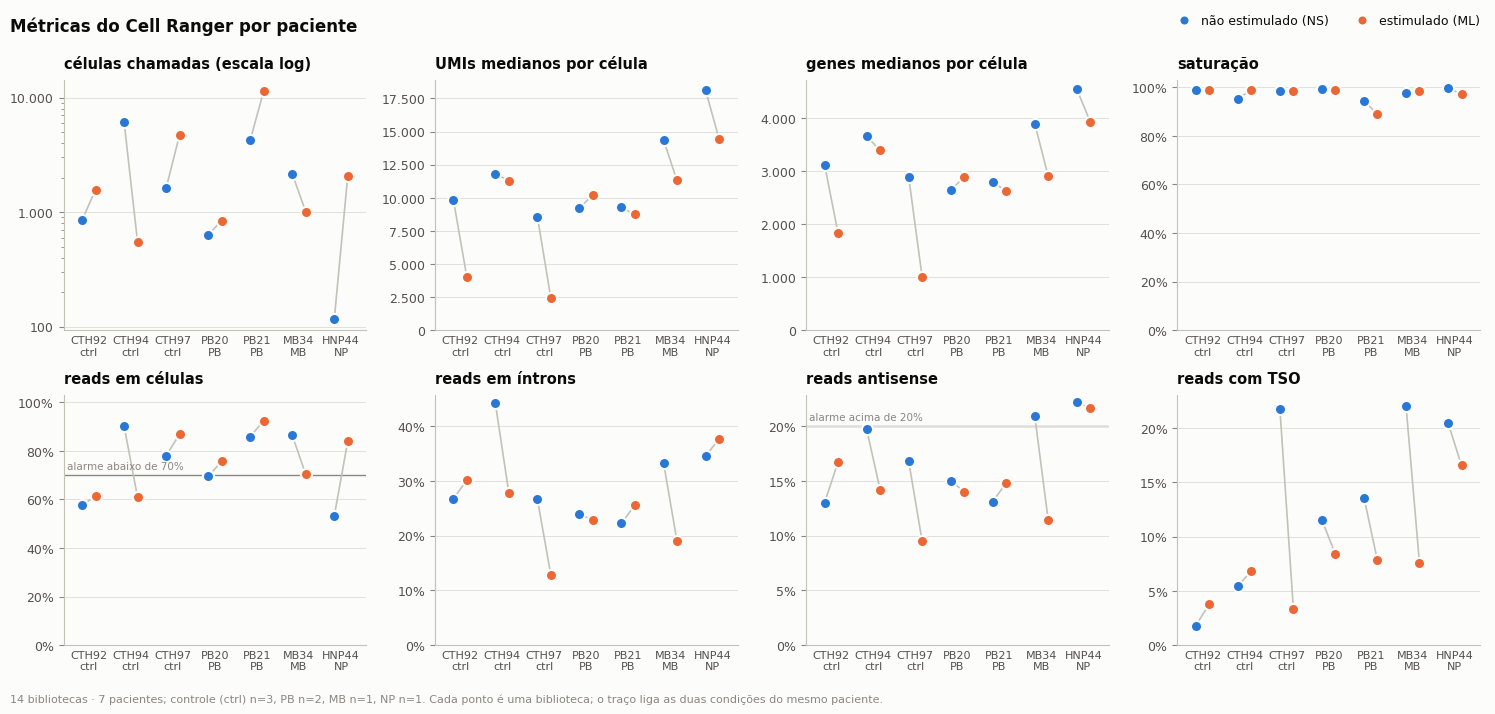

In [12]:
paineis = [
    ("celulas", "células chamadas (escala log)", "log", None, None),
    ("umis_medianos", "UMIs medianos por célula", "n", None, None),
    ("genes_medianos", "genes medianos por célula", "n", None, None),
    ("saturacao", "saturação", "pct1", None, None),
    ("reads_em_celulas", "reads em células", "pct1", 0.70, "alarme abaixo de 70%"),
    ("conf_intronico", "reads em íntrons", "pct", None, None),
    ("antisense", "reads antisense", "pct", 0.20, "alarme acima de 20%"),
    ("tso_frac", "reads com TSO", "pct", None, None),
]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.8))
for ax, (col, titulo, tipo, ref, reftxt) in zip(axes.ravel(), paineis):
    plotting.paired_dots(ax, m[col], log=(tipo == "log"))
    ax.set_title(titulo, fontsize=10.5)
    if tipo == "n":
        plotting.thousands(ax)
        ax.set_ylim(0, None)
    elif tipo == "log":
        plotting.thousands(ax)
    else:
        plotting.percent(ax)
        ax.set_ylim(0, 1.03 if tipo == "pct1" else None)
    if ref is not None:
        ax.axhline(ref, color=INK["muted"], lw=1, zorder=0)
        ax.annotate(reftxt, (0.01, ref), xycoords=("axes fraction", "data"),
                    textcoords="offset points", xytext=(0, 3), ha="left", va="bottom",
                    fontsize=7.5, color=INK["muted"])
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plotting.stim_legend(fig, loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Métricas do Cell Ranger por paciente", x=0.01, y=0.985, ha="left",
             fontsize=12, fontweight="bold")
plotting.note(fig, f"{plotting.N_DESIGN}; controle (ctrl) n=3, PB n=2, MB n=1, NP n=1. "
                   "Cada ponto é uma biblioteca; o traço liga as duas condições do mesmo paciente.")
plotting.savefig(fig, NB, "metricas_por_paciente",
                 description="Métricas do Cell Ranger por paciente e estímulo",
                 data=m[[p[0] for p in paineis]])
plt.show()

In [13]:
poucas = m.index[m["celulas"] < 1000].tolist()
razao = m["celulas"].max() / m["celulas"].min()
baixa_frac = m.index[m["reads_em_celulas"] < 0.70].tolist()
alto_anti = m.index[m["antisense"] > 0.20].tolist()
alto_tso = m.index[m["tso_frac"] > 0.10].tolist()
baixa_cx = m.index[m["genes_medianos"] < 2000].tolist()
frac_pb21 = m.loc[[l for l in LIBS if l.startswith("PB21")], "celulas"].sum() / m["celulas"].sum()
rho_cells_frac = m["celulas"].corr(m["reads_em_celulas"], method="spearman")
rho_intron_anti = m["conf_intronico"].corr(m["antisense"], method="spearman")

print(f"células: total {F.n(m['celulas'].sum())}; menos de 1.000 em {len(poucas)} bibliotecas {poucas}")
print(f"  maior/menor: {m['celulas'].idxmax()} {F.n(m['celulas'].max())} / "
      f"{m['celulas'].idxmin()} {F.n(m['celulas'].min())} = {F.x(razao, 0)}; "
      f"PB21 soma {F.pct(frac_pb21, 0)} das células")
print(f"reads em células < 70%: {baixa_frac}")
print(f"antisense > 20%: {alto_anti}")
print(f"íntrons: {F.pct(m['conf_intronico'].min(), 0)} a {F.pct(m['conf_intronico'].max(), 0)}")
print(f"TSO > 10%: {alto_tso}")
print(f"genes medianos < 2.000: {baixa_cx}")
for lib in baixa_cx:
    par = lib[:-2] + "NS"
    print(f"  {lib}: {F.n(m.loc[lib, 'genes_medianos'])} genes, {F.n(m.loc[lib, 'umis_medianos'])} UMIs "
          f"| par {par}: {F.n(m.loc[par, 'genes_medianos'])} genes, {F.n(m.loc[par, 'umis_medianos'])} UMIs")
print(f"\nSpearman entre as 14 bibliotecas (descritivo): células × reads em células = "
      f"{F.f(rho_cells_frac, 2)}; íntrons × antisense = {F.f(rho_intron_anti, 2)}")

células: total 37.898; menos de 1.000 em 5 bibliotecas ['CTH92_NS', 'CTH94_ML', 'PB20_NS', 'PB20_ML', 'HNP44_NS']
  maior/menor: PB21_ML 11.374 / HNP44_NS 117 = 97×; PB21 soma 41% das células
reads em células < 70%: ['CTH92_NS', 'CTH92_ML', 'CTH94_ML', 'PB20_NS', 'HNP44_NS']
antisense > 20%: ['MB34_NS', 'HNP44_NS', 'HNP44_ML']
íntrons: 13% a 44%
TSO > 10%: ['CTH97_NS', 'PB20_NS', 'PB21_NS', 'MB34_NS', 'HNP44_NS', 'HNP44_ML']
genes medianos < 2.000: ['CTH92_ML', 'CTH97_ML']
  CTH92_ML: 1.832 genes, 4.040 UMIs | par CTH92_NS: 3.121 genes, 9.866 UMIs
  CTH97_ML: 1.009 genes, 2.401 UMIs | par CTH97_NS: 2.894 genes, 8.578 UMIs

Spearman entre as 14 bibliotecas (descritivo): células × reads em células = 0,93; íntrons × antisense = 0,85


**Leitura.**

* *Células.* A recuperação é baixa e muito desigual. Isso não depende de
  profundidade: o número de células é definido na captura.
* *Reads em células.* As bibliotecas com menos células são as que têm menor
  fração de reads em células. Parte disso é aritmética — com um fundo de RNA
  ambiente parecido, quanto menos células, maior a fatia do fundo —, mas o
  resultado prático é o mesmo: nessas bibliotecas o RNA ambiente pesa mais em
  cada célula. A contaminação é medida em A02.
* *Íntrons e antisense.* As duas frações andam juntas entre bibliotecas, o
  padrão de RNA nuclear/não processado. O alarme do Cell Ranger cita núcleos
  isolados como o caso em que isso é esperado; em células inteiras, sugere
  perda de citoplasma. A fração intrônica por célula é examinada em A02.
* *Complexidade.* Duas bibliotecas estimuladas de controles têm poucos genes
  por célula mesmo saturadas, e o par não estimulado do mesmo paciente tem 2 a
  3 vezes mais: não é característica do doador.

In [14]:
log.add("MAJOR", "captura de células",
        "baixa recuperação de células, e muito desigual entre bibliotecas",
        evidence=f"{len(poucas)} de 14 bibliotecas com menos de 1.000 células "
                 f"({', '.join(poucas)}); {m['celulas'].idxmin()} com {F.n(m['celulas'].min())}; "
                 f"razão maior/menor {F.x(razao, 0)}; {F.pct(frac_pb21, 0)} das células vêm de PB21",
        impact="proporções e pseudobulk instáveis nas bibliotecas pequenas; análises por "
               "célula ficam dominadas por um paciente; a profundidade não corrige isso",
        recommendation="tratar bibliotecas com menos de ~200 células como não avaliáveis em "
                       "composição; estatística no nível de biblioteca/paciente; ver A03 para "
                       "as hipóteses sobre a causa")
log.add("MAJOR", "Fraction Reads in Cells",
        f"fração de reads em células abaixo do ideal em {len(baixa_frac)} bibliotecas (alarme do Cell Ranger)",
        evidence="; ".join(f"{l} {F.pct(m.loc[l, 'reads_em_celulas'])}" for l in baixa_frac)
                 + f"; Spearman com nº de células {F.f(rho_cells_frac, 2)} (n=14)",
        impact="RNA ambiente proporcionalmente alto: transcritos abundantes de outras células "
               "aparecem em todas, o que cria falsos positivos de baixa contagem",
        recommendation="estimar a contaminação por biblioteca e decidir sobre correção de "
                       "RNA ambiente (A02)")
log.add("MINOR", "Reads Mapped Antisense / Intronic",
        "fração alta de reads antisense e intrônicos",
        evidence=f"antisense > 20% em {', '.join(alto_anti)}; íntrons de "
                 f"{F.pct(m['conf_intronico'].min(), 0)} a {F.pct(m['conf_intronico'].max(), 0)}; "
                 f"Spearman íntrons × antisense {F.f(rho_intron_anti, 2)} (n=14)",
        impact="indica proporção elevada de RNA nuclear; com include_introns=True essas "
               "moléculas entram na contagem. Compatível com células que perderam citoplasma",
        recommendation="usar a fração intrônica por célula como métrica de QC (A02)")
log.add("MINOR", "diagnostics.tso_frac",
        "fração de reads com sequência de TSO elevada em parte das bibliotecas",
        evidence="; ".join(f"{l} {F.pct(m.loc[l, 'tso_frac'], 0)}" for l in alto_tso),
        impact="sem alarme do Cell Ranger e sem efeito direto na contagem; sugere insertos "
               "curtos de cDNA nessas bibliotecas",
        recommendation="registrar; conferir o perfil de tamanho do cDNA dessas bibliotecas "
                       "se houver traço do Bioanalyzer/TapeStation")
log.add("MAJOR", ", ".join(baixa_cx),
        "complexidade por célula muito baixa em bibliotecas estimuladas de controles",
        evidence="; ".join(
            f"{l}: {F.n(m.loc[l, 'genes_medianos'])} genes e {F.n(m.loc[l, 'umis_medianos'])} UMIs "
            f"medianos com saturação {F.pct(m.loc[l, 'saturacao'])}, contra "
            f"{F.n(m.loc[l[:-2] + 'NS', 'genes_medianos'])} genes em {l[:-2]}NS" for l in baixa_cx),
        impact="essas bibliotecas têm 2–3× menos moléculas por célula que o par do mesmo "
               "paciente; diferenças estimulado × não estimulado nesses pacientes confundem "
               "biologia com eficiência de captura",
        recommendation="caracterizar essas bibliotecas antes de usá-las em contrastes (A02)")

## 5. Chamada de células e composição automática

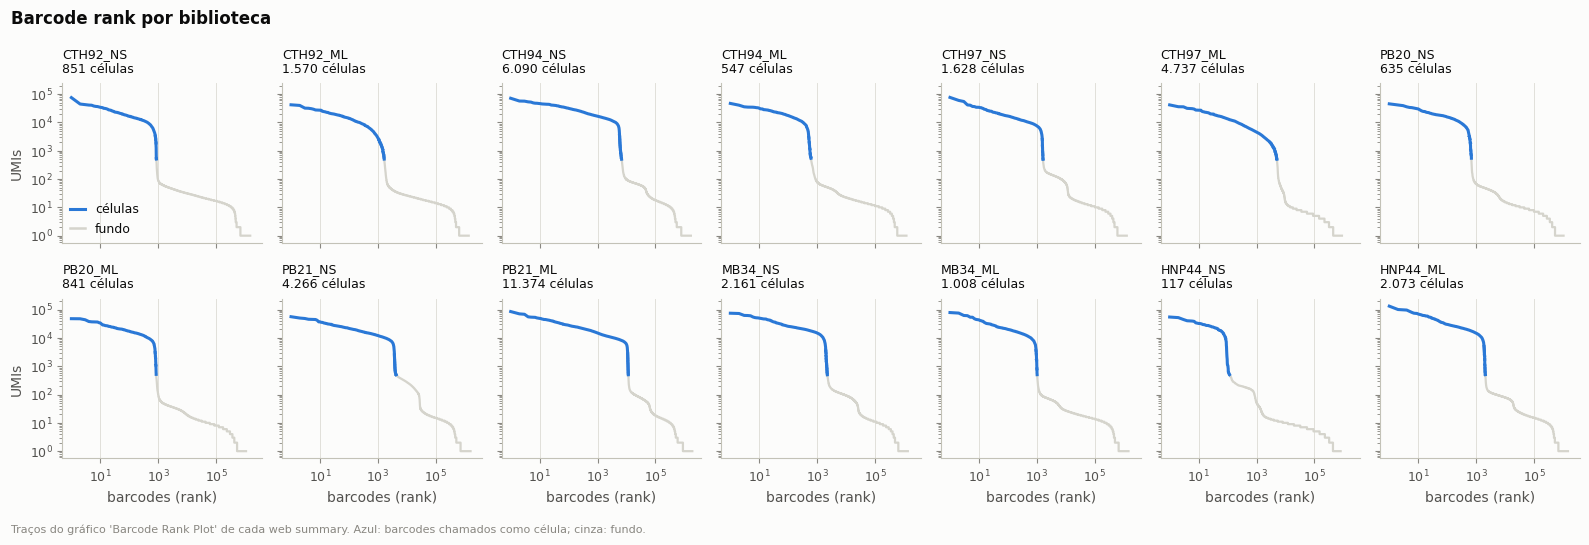

In [15]:
fig, axes = plt.subplots(2, 7, figsize=(16, 5.2), sharex=True, sharey=True)
knee_rows = []
for ax, lib in zip(axes.ravel(), LIBS):
    kp = WS[lib]["summary_tab"]["cells"]["barcode_knee_plot"]["data"]
    for tr in kp:
        fundo = tr["name"] == "Background"
        ax.plot(tr["x"], tr["y"], color=plotting.CONTEXT if fundo else plotting.ACCENT,
                lw=1.6 if fundo else 2.2, zorder=2 if fundo else 3)
        knee_rows.append(pd.DataFrame({"library_id": lib, "rank": tr["x"], "umis": tr["y"],
                                       "classe": tr["name"],
                                       "densidade_celulas": tr.get("cell_density")}))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{lib}\n{F.n(m.loc[lib, 'celulas'])} células", fontsize=9, fontweight="normal")
    ax.grid(axis="both")
for ax in axes[-1]:
    ax.set_xlabel("barcodes (rank)")
for ax in axes[:, 0]:
    ax.set_ylabel("UMIs")
handles = [mpl.lines.Line2D([], [], color=plotting.ACCENT, lw=2.2, label="células"),
           mpl.lines.Line2D([], [], color=plotting.CONTEXT, lw=1.8, label="fundo")]
axes[0, 0].legend(handles=handles, loc="lower left")
fig.suptitle("Barcode rank por biblioteca", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plotting.note(fig, "Traços do gráfico 'Barcode Rank Plot' de cada web summary. "
                   "Azul: barcodes chamados como célula; cinza: fundo.")
knee = pd.concat(knee_rows, ignore_index=True)
plotting.savefig(fig, NB, "barcode_rank",
                 description="Barcode rank plot por biblioteca (dados do web summary)",
                 data=knee, data_index=False)
plt.show()

In [16]:
piso = knee[knee["classe"] == "Cells"].groupby("library_id")["umis"].min()
print(f"menor contagem de UMIs entre barcodes chamados como célula: de {F.n(piso.min())} a "
      f"{F.n(piso.max())} nas 14 bibliotecas")

menor contagem de UMIs entre barcodes chamados como célula: de 500 a 545 nas 14 bibliotecas


Em todas as bibliotecas o limite inferior fica em ~500 UMIs: é o piso do
passo EmptyDrops do Cell Ranger, não um joelho natural da curva. Barcodes
logo acima desse piso entram como célula por diferirem do perfil ambiente,
não por terem conteúdo de célula íntegra. Várias bibliotecas também mostram
um "ombro" no fundo, entre ~50 e ~500 UMIs: barcodes com mais RNA que uma
gota vazia e menos que uma célula. Quantos são e o que são, em A02.

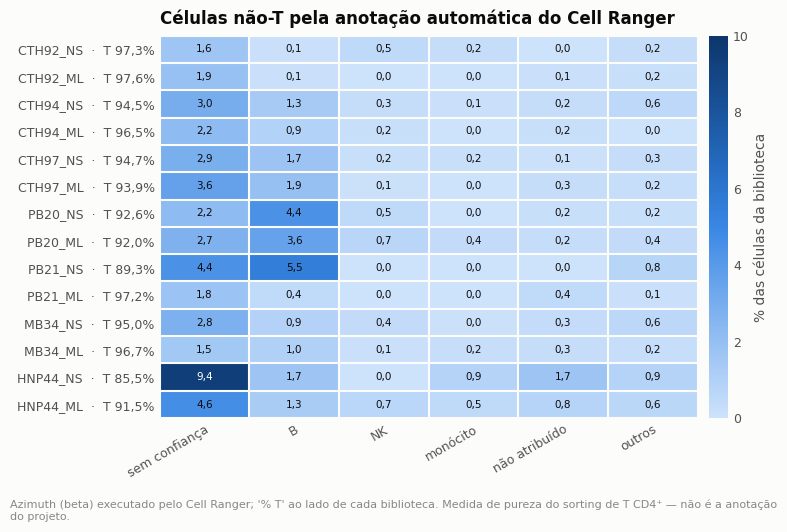

rótulos finos mais frequentes (todas as bibliotecas):
  Naive CD4 T cell                 72,2%
  Memory CD4 T cell                11,5%
  Treg cell                        8,2%
  Fine Not Confidently Annotated   2,8%
  GZMB CD8 T cell                  2,0%
  Plasma cell                      1,0%
  Naive B cell                     0,3%
  Memory B cell                    0,3%

T por biblioteca: 85,5% a 97,6%; B: até 5,5% (PB21_NS)


In [17]:
ct = {lib: io.read_celltypes(lib) for lib in LIBS}
for lib in LIBS:
    assert len(ct[lib]) == int(m.loc[lib, "celulas"]), lib

coarse = pd.DataFrame({lib: ct[lib]["coarse_cell_type"].value_counts(normalize=True)
                       for lib in LIBS}).T.fillna(0)
principais = ["T cell", "Coarse Not Confidently Annotated", "B cell", "NK cell", "Monocyte", "Unassigned"]
comp = coarse[principais].copy()
comp["outros"] = 1 - comp.sum(axis=1)
comp.columns = ["T", "sem confiança", "B", "NK", "monócito", "não atribuído", "outros"]
comp.index.name = "library_id"
io.save_table(comp, NB, "composicao_automatica",
              description="Fração de células por tipo amplo (Azimuth do Cell Ranger)")

nao_t = comp.drop(columns="T") * 100
nao_t.index = [f"{lib}  ·  T {F.pct(comp.loc[lib, 'T'])}" for lib in comp.index]
fig, ax = plt.subplots(figsize=(7.8, 5.0))
plotting.heatmap(ax, nao_t, fmt=".1f", cbar_label="% das células da biblioteca",
                 vmin=0, vmax=10, xrotation=30)
ax.set_title("Células não-T pela anotação automática do Cell Ranger")
fig.tight_layout()
plotting.note(fig, "Azimuth (beta) executado pelo Cell Ranger; '% T' ao lado de cada biblioteca. "
                   "Medida de pureza do sorting de T CD4⁺ — não é a anotação do projeto.")
plotting.savefig(fig, NB, "composicao_automatica",
                 description="Células não-T por biblioteca (anotação automática do Cell Ranger)",
                 data=comp)
plt.show()

fino = pd.concat([ct[lib]["fine_cell_type"] for lib in LIBS]).value_counts(normalize=True)
print("rótulos finos mais frequentes (todas as bibliotecas):")
for rotulo, v in fino.head(8).items():
    print(f"  {rotulo:32s} {F.pct(v)}")
print(f"\nT por biblioteca: {F.pct(comp['T'].min())} a {F.pct(comp['T'].max())}; "
      f"B: até {F.pct(comp['B'].max())} ({comp['B'].idxmax()})")

In [18]:
log.add("INFO", "cell_types/Azimuth",
        "pureza do sorting: a grande maioria das células é T, com contaminantes em poucos %",
        evidence=f"T de {F.pct(comp['T'].min())} a {F.pct(comp['T'].max())} por biblioteca; B até "
                 f"{F.pct(comp['B'].max())} ({comp['B'].idxmax()}); "
                 f"{F.pct(fino.get('Naive CD4 T cell', 0), 0)} das células rotuladas 'Naive CD4 T cell'",
        impact="os contaminantes são poucos, mas existem em todas as bibliotecas; servem de "
               "controle interno para estimar doublets heterotípicos (A03). A predominância "
               "de células naive é coerente com poucas células produzindo citocina",
        recommendation="remover não-T na etapa de anotação, como no fluxo anterior")

## 6. Problemas encontrados neste nível

In [19]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    1
MAJOR       3
MINOR       3
INFO        2


severity,location,problem,evidence,impact,recommendation
CRITICAL,todas as bibliotecas — profundidade × complexidade,as bibliotecas estão saturadas: o sequenciamento adicional lê repetidamente as mesmas moléculas,"saturação final 89,0%–99,5% (≥ 95% em 12/14); mediana de 70 reads por UMI (máx. 217); profundidade 7×–638× o mínimo da 10x; 90% dos genes por célula já apareciam com 10% dos reads (mediana); a última duplicação de profundidade rendeu +2,3% de genes e +3,0% de UMIs","retorno fortemente decrescente para 26,11 bi de reads. Sequenciar mais as mesmas bibliotecas não tem de onde tirar moléculas novas; o efeito sobre as citocinas é medido em C02 e C03","não sequenciar mais estas bibliotecas. Mais sinal exige mais moléculas: mais células por biblioteca ou enriquecimento das células de interesse, não mais reads"
MAJOR,captura de células,"baixa recuperação de células, e muito desigual entre bibliotecas","5 de 14 bibliotecas com menos de 1.000 células (CTH92_NS, CTH94_ML, PB20_NS, PB20_ML, HNP44_NS); HNP44_NS com 117; razão maior/menor 97×; 41% das células vêm de PB21",proporções e pseudobulk instáveis nas bibliotecas pequenas; análises por célula ficam dominadas por um paciente; a profundidade não corrige isso,tratar bibliotecas com menos de ~200 células como não avaliáveis em composição; estatística no nível de biblioteca/paciente; ver A03 para as hipóteses sobre a causa
MAJOR,Fraction Reads in Cells,fração de reads em células abaixo do ideal em 5 bibliotecas (alarme do Cell Ranger),"CTH92_NS 57,6%; CTH92_ML 61,3%; CTH94_ML 60,8%; PB20_NS 69,5%; HNP44_NS 53,2%; Spearman com nº de células 0,93 (n=14)","RNA ambiente proporcionalmente alto: transcritos abundantes de outras células aparecem em todas, o que cria falsos positivos de baixa contagem",estimar a contaminação por biblioteca e decidir sobre correção de RNA ambiente (A02)
MAJOR,"CTH92_ML, CTH97_ML",complexidade por célula muito baixa em bibliotecas estimuladas de controles,"CTH92_ML: 1.832 genes e 4.040 UMIs medianos com saturação 98,8%, contra 3.121 genes em CTH92_NS; CTH97_ML: 1.009 genes e 2.401 UMIs medianos com saturação 98,6%, contra 2.894 genes em CTH97_NS",essas bibliotecas têm 2–3× menos moléculas por célula que o par do mesmo paciente; diferenças estimulado × não estimulado nesses pacientes confundem biologia com eficiência de captura,caracterizar essas bibliotecas antes de usá-las em contrastes (A02)
MINOR,data/allOuts — nomes das pastas,nomes das bibliotecas diferem dos usados na corrida anterior; duas usam o sufixo SN em vez de NS,"8 de 14 pastas renomeadas; SN: ['PB_20_SN', 'MB_34_SN']","a regra original `endswith('NS')` rotularia MB_34_SN e PB_20_SN como estimuladas, invertendo a condição de 2 das 14 bibliotecas sem erro algum",usar o library_id canônico em todo o código (feito) e padronizar os nomes na origem em corridas futuras
MINOR,Reads Mapped Antisense / Intronic,fração alta de reads antisense e intrônicos,"antisense > 20% em MB34_NS, HNP44_NS, HNP44_ML; íntrons de 13% a 44%; Spearman íntrons × antisense 0,85 (n=14)",indica proporção elevada de RNA nuclear; com include_introns=True essas moléculas entram na contagem. Compatível com células que perderam citoplasma,usar a fração intrônica por célula como métrica de QC (A02)
MINOR,diagnostics.tso_frac,fração de reads com sequência de TSO elevada em parte das bibliotecas,CTH97_NS 22%; PB20_NS 12%; PB21_NS 14%; MB34_NS 22%; HNP44_NS 20%; HNP44_ML 17%,sem alarme do Cell Ranger e sem efeito direto na contagem; sugere insertos curtos de cDNA nessas bibliotecas,registrar; conferir o perfil de tamanho do cDNA dessas bibliotecas se houver traço do Bioanalyzer/TapeStation
INFO,cellranger count --create-bam=false,as corridas não geraram BAM,_cmdline das 14 bibliotecas,sem alinhamentos não há reconstrução de TCR nem genotipagem; a hipótese de doublets só pode ser testada por evidência indireta,"se a prova direta de doublets for necessária, reprocessar com --create-bam=true (ainda assim, com um doador por biblioteca

## Conclusão

O sequenciamento funcionou: qualidade de base, barcodes válidos e
mapeamento estão altos em todas as bibliotecas, e o Cell Ranger só levantou
alarmes sobre fração de reads em células e reads antisense.

O problema é a relação entre profundidade e biblioteca. Cada molécula foi
lida dezenas a centenas de vezes, e o retorno em genes por célula no trecho
final da curva é de poucos pontos percentuais. Número de células e
complexidade por célula são fixados na preparação; nenhum dos dois melhora
com mais leitura.

Os notebooks seguintes quantificam isso contra a corrida antiga (C02) e
molécula a molécula, incluindo as citocinas (C03).

In [20]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

14 artefatos gravados por este notebook:
                       name   kind
               proveniencia  table
    metricas_por_biblioteca  table
         alarmes_cellranger  table
    retorno_da_profundidade  table
fig_retorno_da_profundidade figure
fig_retorno_da_profundidade  table
  fig_metricas_por_paciente figure
  fig_metricas_por_paciente  table
           fig_barcode_rank figure
           fig_barcode_rank  table
      composicao_automatica  table
  fig_composicao_automatica figure
  fig_composicao_automatica  table
                     issues  table
